Data preprocessing

In [90]:
!pip install -q numpy pandas matplotlib seaborn scikit-learn joblib tqdm

In [2]:
import os
import glob
import joblib
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

In [25]:
ROOT = "/content"

WINDOW_SECONDS = 2
RATE = 50

WINDOW_SIZE = WINDOW_SECONDS * RATE
STEP_SIZE = WINDOW_SIZE

ACTION_FOLDER = os.path.join(ROOT, "windows", "action")
NOACTION_FOLDER = os.path.join(ROOT, "windows", "noaction")

os.makedirs(ACTION_FOLDER, exist_ok=True)
os.makedirs(NOACTION_FOLDER, exist_ok=True)

In [27]:
csv_files = sorted(glob.glob(os.path.join(ROOT, "*.csv")))

print(f"Found {len(csv_files)} csv files\n")

for f in csv_files:
    print(os.path.basename(f))

Found 8 csv files

P01_action_amrith_20260717_mixed.csv
P01_action_amrith_20260717_walk.csv
P01_action_rishiikesh_20260717_mixed.csv
P01_action_rishiikesh_20260717_walk.csv
P01_noaction_amrith_20260717_sit.csv
P01_noaction_amrith_20260717_stand.csv
P01_noaction_rishiikesh_20260717_sit.csv
P01_noaction_rishiikesh_20260717_stand.csv


In [28]:
def amplitude_from_dataframe(df):

    re_cols = [c for c in df.columns if c.endswith("_Re")]
    im_cols = [c for c in df.columns if c.endswith("_Im")]

    re = df[re_cols].values
    im = df[im_cols].values

    amp = np.sqrt(re**2 + im**2)

    return amp

In [29]:
summary = []

for file in csv_files:

    df = pd.read_csv(file)

    amp = amplitude_from_dataframe(df)

    rows = len(df)

    duration = rows / RATE

    summary.append({

        "File":os.path.basename(file),

        "Rows":rows,

        "Duration(s)":round(duration,2),

        "NaNs":np.isnan(amp).sum()

    })

summary = pd.DataFrame(summary)

summary

,File,Rows,Duration(s),NaNs
0,P01_action_amrith_20260717_mixed.csv,7930,158.60,4
1,P01_action_amrith_20260717_walk.csv,6708,134.16,19
2,P01_action_rishiikesh_20260717_mixed.csv,5381,107.62,19
3,P01_action_rishiikesh_20260717_walk.csv,7115,142.30,8
4,P01_noaction_amrith_20260717_sit.csv,6516,130.32,41
5,P01_noaction_amrith_20260717_stand.csv,6047,120.94,46
6,P01_noaction_rishiikesh_20260717_sit.csv,4680,93.60,14
7,P01_noaction_rishiikesh_20260717_stand.csv,5644,112.88,31


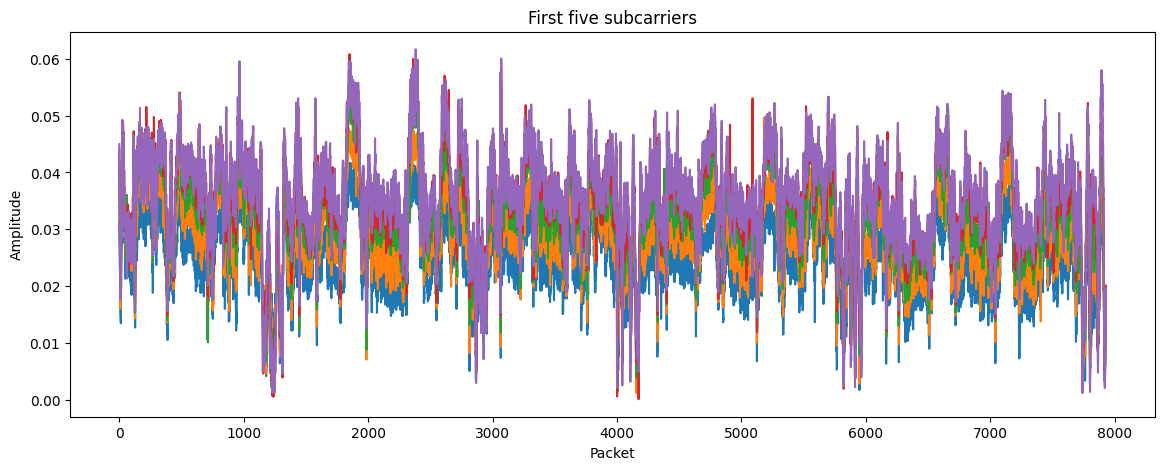

In [30]:
df = pd.read_csv(csv_files[0])

amp = amplitude_from_dataframe(df)

plt.figure(figsize=(14,5))

for i in range(5):
    plt.plot(amp[:,i])

plt.title("First five subcarriers")

plt.xlabel("Packet")

plt.ylabel("Amplitude")

plt.show()

In [31]:
def create_windows(signal):

    windows=[]

    for start in range(
            0,
            len(signal)-WINDOW_SIZE+1,
            STEP_SIZE):

        end=start+WINDOW_SIZE

        windows.append(signal[start:end])

    return np.array(windows)

In [32]:
all_packets=[]

for file in csv_files:

    df=pd.read_csv(file)

    amp=amplitude_from_dataframe(df)

    all_packets.append(amp)

all_packets=np.vstack(all_packets)

scaler=StandardScaler()

scaler.fit(all_packets)

joblib.dump(
    scaler,
    os.path.join(ROOT,"scaler.pkl")
)

print("Scaler saved.")

Scaler saved.


In [33]:
metadata=[]

counter=0

for file in tqdm(csv_files):

    df=pd.read_csv(file)

    amp=amplitude_from_dataframe(df)

    amp=scaler.transform(amp)

    windows=create_windows(amp)

    filename = os.path.basename(file).lower()

    if "_noaction_" in filename:
        label = "noaction"
    elif "_action_" in filename:
        label = "action"
    else:
        raise ValueError(f"Cannot determine label for {filename}")

    subject="rishiikesh" if "rishiikesh" in file else "amrith"

    take=os.path.basename(file).split("_")[-1].replace(".csv","")

    save_folder=ACTION_FOLDER if label=="action" else NOACTION_FOLDER

    for w in windows:

        name=f"{subject}_{take}_{counter}.npy"

        np.save(
            os.path.join(save_folder,name),
            w
        )

        metadata.append({

            "file":name,

            "label":label,

            "subject":subject,

            "take":take

        })

        counter+=1

100%|██████████| 8/8 [00:01<00:00,  7.60it/s]


In [34]:
metadata=pd.DataFrame(metadata)

metadata.to_csv(

    os.path.join(ROOT,"metadata.csv"),

    index=False

)

metadata.head()

,file,label,subject,take
0,amrith_mixed_0.npy,action,amrith,mixed
1,amrith_mixed_1.npy,action,amrith,mixed
2,amrith_mixed_2.npy,action,amrith,mixed
3,amrith_mixed_3.npy,action,amrith,mixed
4,amrith_mixed_4.npy,action,amrith,mixed


In [35]:
metadata["label"].value_counts()

,count
label,
action,270
noaction,227


In [36]:
metadata["subject"].value_counts()

,count
subject,
amrith,271
rishiikesh,226


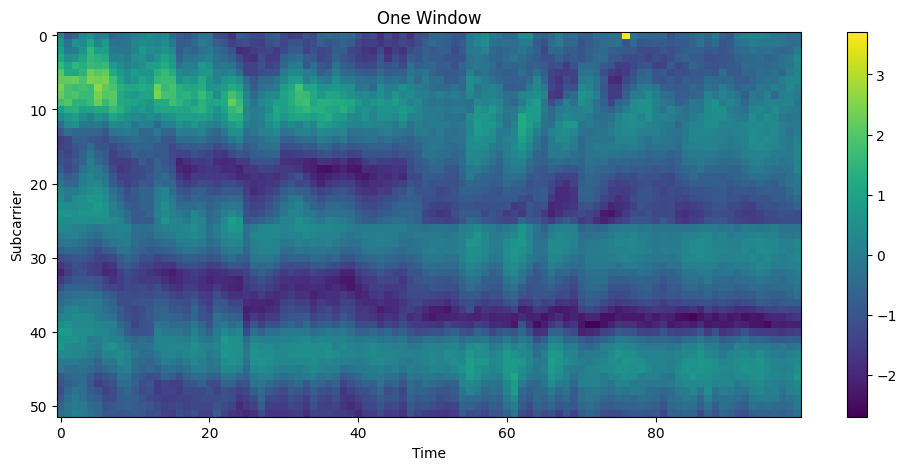

In [37]:
sample=np.load(

    glob.glob("/content/windows/action/*.npy")[0]

)

plt.figure(figsize=(12,5))

plt.imshow(sample.T,aspect="auto")

plt.colorbar()

plt.xlabel("Time")

plt.ylabel("Subcarrier")

plt.title("One Window")

plt.show()

In [38]:
print("="*50)

print("Action windows :",

      len(glob.glob("/content/windows/action/*.npy")))

print("NoAction windows :",

      len(glob.glob("/content/windows/noaction/*.npy")))

print("="*50)

Action windows : 270
NoAction windows : 227


Training

In [39]:
!pip -q install torch torchvision torchaudio scipy tqdm scikit-learn

In [40]:
import os
import glob
import joblib
import random

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

from tqdm import tqdm

from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from torchvision import models
from torchvision import transforms

In [41]:
ROOT="/content"

WINDOW_FOLDER=os.path.join(ROOT,"windows")

META=os.path.join(ROOT,"metadata.csv")

MODEL_FOLDER=os.path.join(ROOT,"models")

os.makedirs(MODEL_FOLDER,exist_ok=True)

DEVICE=torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(DEVICE)

cuda


In [42]:
meta=pd.read_csv(META)

meta.head()

,file,label,subject,take
0,amrith_mixed_0.npy,action,amrith,mixed
1,amrith_mixed_1.npy,action,amrith,mixed
2,amrith_mixed_2.npy,action,amrith,mixed
3,amrith_mixed_3.npy,action,amrith,mixed
4,amrith_mixed_4.npy,action,amrith,mixed


In [43]:
print(meta["label"].value_counts())

print()

print(meta["subject"].value_counts())

label
action      270
noaction    227
Name: count, dtype: int64

subject
amrith        271
rishiikesh    226
Name: count, dtype: int64


In [44]:
def recurrence_plot(signal):

    signal=signal.reshape(-1,1)

    dist=squareform(
        pdist(signal,
              metric="euclidean")
    )

    return dist

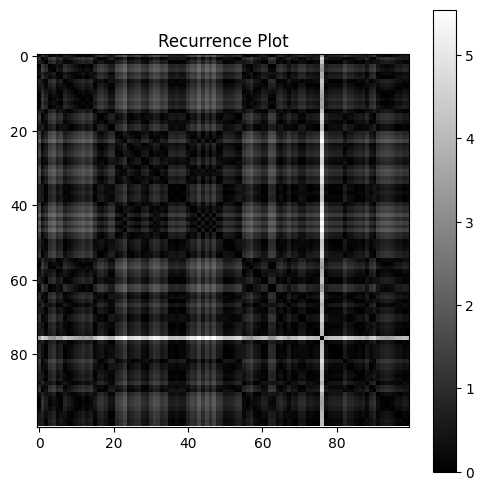

In [45]:
sample=np.load(

glob.glob("/content/windows/action/*.npy")[0]

)

rp=recurrence_plot(sample[:,0])

plt.figure(figsize=(6,6))

plt.imshow(rp,cmap="gray")

plt.title("Recurrence Plot")

plt.colorbar()

plt.show()

In [46]:
transform=transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=[0.485],

        std=[0.229]

    )

])

In [47]:
def get_window_path(filename, label):

    folder = "action" if label == "action" else "noaction"

    return os.path.join(
        ROOT,
        "windows",
        folder,
        filename
    )

In [48]:
class ImgFiDataset(Dataset):

    def __init__(self,
                 dataframe,
                 transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

        self.label_map = {
            "action":1,
            "noaction":0
        }

    def __len__(self):

        return len(self.df)*52

    def __getitem__(self,index):

        window_index = index // 52

        subcarrier = index % 52

        row = self.df.iloc[window_index]

        path = get_window_path(
            row.file,
            row.label
        )

        window = np.load(path)

        signal = window[:,subcarrier]

        rp = recurrence_plot(signal)

        rp = rp.astype(np.float32)

        rp -= rp.min()

        rp /= (rp.max()+1e-8)

        if self.transform:

            rp = self.transform(rp)

        label = self.label_map[row.label]

        return rp,label,window_index

In [49]:
dataset = ImgFiDataset(
    meta,
    transform
)

print(len(dataset))

25844


In [50]:
image,label,window = dataset[0]

print(image.shape)

print(label)

torch.Size([1, 224, 224])
1


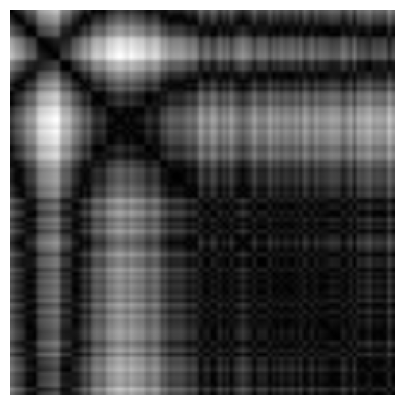

In [51]:
plt.figure(figsize=(5,5))

plt.imshow(
    image.squeeze(),
    cmap="gray"
)

plt.axis("off")

plt.show()

In [52]:
subjects = sorted(
    meta.subject.unique()
)

subjects

['amrith', 'rishiikesh']

In [53]:
def create_split(test_subject):

    train_df = meta[
        meta.subject!=test_subject
    ]

    test_df = meta[
        meta.subject==test_subject
    ]

    return train_df,test_df

In [54]:
train_df,test_df = create_split(
    "amrith"
)

print(len(train_df))

print(len(test_df))

226
271


In [55]:
train_dataset = ImgFiDataset(
    train_df,
    transform
)

test_dataset = ImgFiDataset(
    test_df,
    transform
)

In [56]:
train_loader = DataLoader(

    train_dataset,

    batch_size=64,

    shuffle=True,

    num_workers=2,

    pin_memory=True

)

test_loader = DataLoader(

    test_dataset,

    batch_size=64,

    shuffle=False,

    num_workers=2,

    pin_memory=True

)

In [57]:
images,labels,windows = next(

iter(train_loader)

)

print(images.shape)

print(labels.shape)

torch.Size([64, 1, 224, 224])
torch.Size([64])


In [58]:
transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize((224,224)),

    transforms.Grayscale(num_output_channels=3),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

In [59]:
train_dataset = ImgFiDataset(
    train_df,
    transform
)

test_dataset = ImgFiDataset(
    test_df,
    transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [60]:
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model = model.to(DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s]


In [61]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [62]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

In [63]:
def train_epoch(model,loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    for images,labels,_ in tqdm(loader):

        images = images.to(DEVICE)

        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs,labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        preds = outputs.argmax(1)

        correct += (preds==labels).sum().item()

        total += labels.size(0)

    loss = running_loss/len(loader)

    acc = correct/total

    return loss,acc

In [64]:
def validate(model,loader):

    model.eval()

    predictions = []

    labels_list = []

    window_ids = []

    with torch.no_grad():

        for images,labels,windows in loader:

            images = images.to(DEVICE)

            outputs = model(images)

            preds = outputs.argmax(1).cpu().numpy()

            predictions.extend(preds)

            labels_list.extend(labels.numpy())

            window_ids.extend(windows.numpy())

    return predictions,labels_list,window_ids

In [65]:
from collections import defaultdict, Counter

def majority_vote(predictions,
                  labels,
                  window_ids):

    pred_dict = defaultdict(list)

    true_dict = {}

    for p,l,w in zip(predictions,
                     labels,
                     window_ids):

        pred_dict[w].append(p)

        true_dict[w] = l

    final_pred = []

    final_true = []

    for w in sorted(pred_dict.keys()):

        vote = Counter(
            pred_dict[w]
        ).most_common(1)[0][0]

        final_pred.append(vote)

        final_true.append(
            true_dict[w]
        )

    return final_true,final_pred

In [66]:
def evaluate(model,loader):

    preds,labels,windows = validate(
        model,
        loader
    )

    y_true,y_pred = majority_vote(
        preds,
        labels,
        windows
    )

    acc = accuracy_score(
        y_true,
        y_pred
    )

    return acc,y_true,y_pred

In [67]:
EPOCHS = 15

best_acc = 0

for epoch in range(EPOCHS):

    train_loss,train_acc = train_epoch(
        model,
        train_loader
    )

    val_acc,y_true,y_pred = evaluate(
        model,
        test_loader
    )

    scheduler.step(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train Loss : {train_loss:.4f}"
    )

    print(
        f"Train Acc  : {train_acc:.4f}"
    )

    print(
        f"Test Acc   : {val_acc:.4f}"
    )

    print()

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            os.path.join(
                MODEL_FOLDER,
                "best_model.pth"
            )
        )

100%|██████████| 184/184 [00:44<00:00,  4.10it/s]


Epoch 1/15
Train Loss : 0.1129
Train Acc  : 0.9569
Test Acc   : 0.9779



100%|██████████| 184/184 [00:38<00:00,  4.82it/s]


Epoch 2/15
Train Loss : 0.0339
Train Acc  : 0.9877
Test Acc   : 0.9668



100%|██████████| 184/184 [00:38<00:00,  4.81it/s]


...

Epoch 13/15
Train Loss : 0.0001
Train Acc  : 1.0000
Test Acc   : 0.9594



100%|██████████| 184/184 [00:38<00:00,  4.83it/s]


Epoch 14/15
Train Loss : 0.0001
Train Acc  : 1.0000
Test Acc   : 0.9631



100%|██████████| 184/184 [00:37<00:00,  4.90it/s]


Epoch 15/15
Train Loss : 0.0002
Train Acc  : 1.0000
Test Acc   : 0.9594



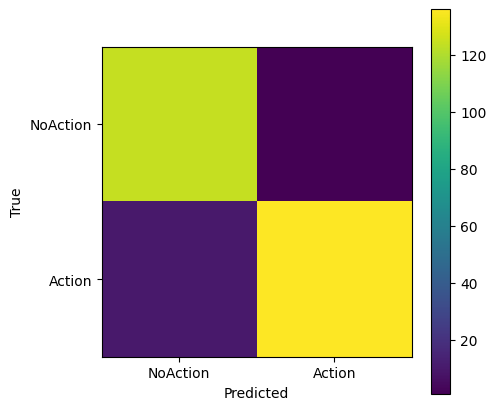

In [68]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(5,5))

plt.imshow(cm)

plt.xticks([0,1],["NoAction","Action"])

plt.yticks([0,1],["NoAction","Action"])

plt.colorbar()

plt.xlabel("Predicted")

plt.ylabel("True")

plt.show()

In [69]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "NoAction",
            "Action"
        ]
    )
)

              precision    recall  f1-score   support

    NoAction       0.93      0.99      0.96       125
      Action       0.99      0.93      0.96       146

    accuracy                           0.96       271
   macro avg       0.96      0.96      0.96       271
weighted avg       0.96      0.96      0.96       271



In [70]:
torch.save(
    model.state_dict(),
    os.path.join(
        MODEL_FOLDER,
        "imgfi_model_fold1.pth"
    )
)

Testing

In [71]:
import joblib

scaler = joblib.load("/content/scaler.pkl")

In [72]:
model = models.resnet18(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model.load_state_dict(
    torch.load(
        "/content/models/imgfi_model_fold1.pth",
        map_location=DEVICE
    )
)

model = model.to(DEVICE)

model.eval()

print("Model Loaded Successfully")

Model Loaded Successfully


In [85]:
TEST_FILE = "/content/P01_action_amrith_20260717_mixed.csv"

In [86]:
df = pd.read_csv(TEST_FILE)

amp = amplitude_from_dataframe(df)

amp = scaler.transform(amp)

windows = create_windows(amp)

print("Windows :", len(windows))

Windows : 79


In [81]:
from collections import Counter

def predict_window(window):

    predictions = []

    for subcarrier in range(52):

        signal = window[:,subcarrier]

        rp = recurrence_plot(signal)

        rp = rp.astype(np.float32)

        rp -= rp.min()

        rp /= (rp.max()+1e-8)

        image = transform(rp)

        image = image.unsqueeze(0)

        image = image.to(DEVICE)

        with torch.no_grad():

            output = model(image)

            pred = output.argmax(1).item()

        predictions.append(pred)

    vote = Counter(predictions).most_common(1)[0][0]

    confidence = predictions.count(vote)/52

    return vote,confidence

In [87]:
window_predictions = []

confidences = []

for window in windows:

    pred,conf = predict_window(window)

    window_predictions.append(pred)

    confidences.append(conf)

In [88]:
final_vote = Counter(
    window_predictions
).most_common(1)[0][0]

overall_confidence = (
    window_predictions.count(final_vote)
    /
    len(window_predictions)
)

In [89]:
label_map = {
    0:"NoAction",
    1:"Action"
}

print("="*50)

print("File")

print(TEST_FILE.split("/")[-1])

print()

print("Total Windows :",len(windows))

print()

print("Window Predictions")

print("Action :",window_predictions.count(1))

print("NoAction :",window_predictions.count(0))

print()

print("Overall Prediction")

print(label_map[final_vote])

print()

print("Confidence :")

print(f"{overall_confidence*100:.2f}%")

print("="*50)

File
P01_action_amrith_20260717_mixed.csv

Total Windows : 79

Window Predictions
Action : 69
NoAction : 10

Overall Prediction
Action

Confidence :
87.34%
